# Viterbi smoothing of the classifier output

Candidates are the maximal runs of non-NOISE frames of the per-frame classifier (`signals.classify()` takes the argmax, `bounded_regions(min_size=10)` cuts at the first NOISE frame and drops runs under 10 frames). The classifier flickers: one NOISE frame splits a whistle, a faint tail labelled NOISE is cut off, and 90% of non-NOISE runs are too short to become candidates. The sub-models then learn whistle fragments.

`dolphin_msa` smooths the classifier output with a small HMM whose emissions are the classifier's softmax probabilities (`lib_dolphin/decoder/build_decoder.py`, `processing.py: decode_vite`). Here the same idea, with this topology:

- **4 states**: NOISE, WHISTLE (UP and DOWN merged, their probabilities summed), ECHO, BURST. Merging the whistle directions means a whistle that turns from UP to DOWN stays one state, so the smoothing can't cut it there.
- **Class self-transitions from L2**: each class's mean motif length in frames, *m*, over the curated L2 regions (the baked candidates in `candidates.pkl`, labelled by their majority class), gives self = 1 - 1/m. A class leaves only to NOISE.
- **NOISE**: stays with 1 - ε, moves to each class with ε/3 (flat). ε is swept.
- **Emissions**: the classifier's probabilities, as in `dolphin_msa`. Uniform start.

The embedding cache only keeps the argmax label, so the probabilities are recomputed with the encoder (same model, same windows; checked against the cached labels) on a subset: the 5 recordings with the highest whistle share, 6,000 frames (~6 min) each. For 05272401_SKATE_TASCAM the segment is placed around the whistle of medoid 31 in `StateInitializationEffect`, whose tail the classifier cut off.

All code is in this notebook; plotting and audio helpers come from `ViterbiSubmodelTrainingEffect.ipynb`.

In [1]:
import os
import sys
import json
import glob
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed

REPO = os.path.abspath('..')
sys.path.insert(0, REPO)

from lib_phmm.signals import LABEL_MAP
from lib_phmm.config import CONFIG

with open(os.path.join(REPO, 'analysis_notebooks', 'ViterbiSubmodelTrainingEffect.ipynb')) as f:
    _cells = json.load(f)['cells']
exec(next(''.join(c['source']) for c in _cells if 'def run_exemplar_sweep' in ''.join(c['source'])))

In [2]:
HANDLER_STATE      = os.path.join(REPO, 'motif', 'handler_state')
EMBEDDINGS_DIR     = os.path.join(HANDLER_STATE, 'motif_embeddings_cache')
EMBEDDINGS_VERSION = 'v2'
CANDIDATES_PATH    = os.path.join(HANDLER_STATE, 'motif_extend_state', 'candidates.pkl')
AUDIO_ROOT         = '/Users/dkohlsdorf/Documents/audio/wdp_data_at_google'
FMAX_HZ            = 30000
PROBS_DIR          = os.path.join(HANDLER_STATE, 'classifier_probs')   # recomputed probabilities, one file per segment
MIN_REGION_FRAMES  = 10          # bounded_regions()' min_size
SEGMENT_FRAMES     = 6000

# the 5 recordings with the highest UP/DOWN share (that have local audio); start frame of the segment
SEGMENTS = {
    '05222401_SKATE_TASCAM':          0,
    '06052401_SKATE_TASCAM (jump 2)': 0,
    '05272401_SKATE_TASCAM':          15000,     # holds medoid 31's whistle at 1021.16 s
    '07312401_EAGLE_TASCAM':          0,
    '06052401_SKATE_TASCAM (jump 1)': 0,
}

CLASSIFIER = [LABEL_MAP[i] for i in range(len(LABEL_MAP))]       # classifier output order
STATES = ['NOISE', 'WHISTLE', 'ECHO', 'BURST']
MERGE = np.zeros((len(CLASSIFIER), len(STATES)))                 # classifier probs -> state probs
for i, c in enumerate(CLASSIFIER):
    MERGE[i, STATES.index('WHISTLE' if c in ('UP', 'DOWN') else c)] = 1
NOISE = 0

cached = {}
for name in SEGMENTS:
    with open(f"{EMBEDDINGS_DIR}/{name}.{EMBEDDINGS_VERSION}.pkl", 'rb') as f:
        _, classifications, step_samples, emb_sr = pickle.load(f)
    cached[name] = (np.array(classifications), step_samples, emb_sr)
STEP_SECONDS = step_samples / emb_sr

def find_files(root, name):
    return sorted(glob.glob(os.path.join(glob.escape(root), '**', name), recursive=True))

audio_index = {}
for ext in ('m4a', 'wav'):
    for p in find_files(AUDIO_ROOT, '*.' + ext):
        audio_index[os.path.splitext(os.path.basename(p))[0]] = p

## Class durations from L2

The baked L2 candidates are the ones that are not a slice of any cached recording.

In [3]:
with open(CANDIDATES_PATH, 'rb') as f:
    candidates = pickle.load(f)

frame_index = set()
for file_name in os.listdir(EMBEDDINGS_DIR):
    if file_name.endswith(f'.{EMBEDDINGS_VERSION}.pkl') and not file_name.startswith('noise_embeddings'):
        with open(f"{EMBEDDINGS_DIR}/{file_name}", 'rb') as f:
            emb = np.asarray(pickle.load(f)[0], dtype=np.float32)
        frame_index.update(e.tobytes() for e in emb)
baked = [c for c in candidates if np.asarray(c[1], dtype=np.float32)[0].tobytes() not in frame_index]

def state_of(label):
    return 'WHISTLE' if label in ('UP', 'DOWN') else label

l2 = pd.DataFrame({"class": [Counter(state_of(l) for l in c[2]).most_common(1)[0][0] for c in baked],
                   "frames": [len(c[2]) for c in baked]})
L2_DURATION = l2[l2["class"] != 'NOISE'].groupby("class")["frames"].mean()
print(f"{len(baked)} baked L2 candidates of {len(candidates)}")
l2.groupby("class")["frames"].describe()[["count", "mean", "50%"]].round(1)

3667 baked L2 candidates of 7383


,count,mean,50%
class,,,
BURST,890.0,24.8,20.0
ECHO,1182.0,59.5,42.0
NOISE,100.0,25.7,21.0
WHISTLE,1495.0,20.7,19.0


## Classifier probabilities for the segments

`process()` + `classify()` are what built the cache; the probabilities are the softmax `classify()` takes the argmax of. Two workers, one on MPS and one on the CPU. On MPS the model's mask pooling (`adaptive_avg_pool2d` with a non-divisible size) isn't implemented, so `embed()` is replaced by the same computation with that one step on the CPU. Results are cached per segment.

In [4]:
def segment_probs(name, start, device):
    import types
    import torch
    import torch.nn.functional as F
    sys.path.insert(0, REPO)                     # loky workers start without the notebook's path
    from motif_discovery import whisper_model_v2, whisper_processor, load_waveform_at
    from lib_phmm.signals import process

    path = os.path.join(PROBS_DIR, f"{name}.{start}.npy")
    if os.path.exists(path):
        return path
    model = whisper_model_v2(model_file=os.path.join(REPO, CONFIG['checkpoint_path']), cuda=False)
    model.eval()
    if device == 'mps':
        def embed(self, input_features, input_mask):
            emb = self.encoder(input_features=input_features).last_hidden_state
            pooled = F.adaptive_avg_pool2d(input_mask.cpu().unsqueeze(1), (1, emb.shape[1])).squeeze(1).squeeze(1).to(emb.device)
            pooled_emb = (emb * pooled.unsqueeze(-1)).sum(1) / pooled.sum(1, keepdim=True).clamp(min=1)
            return emb, self.head_embedding(pooled_emb), pooled
        model.embed = types.MethodType(embed, model)
        model.to('mps')
    processor = whisper_processor()
    _, step, sr = cached[name]
    waveform, _ = load_waveform_at(audio_index[name], sr)
    stop = min(len(cached[name][0]), start + SEGMENT_FRAMES)
    piece = waveform[:, start * step:stop * step + CONFIG['window_size_samples']]
    out = []
    for r in process(piece, model, processor):
        out.append(torch.softmax(r['classifications'][0, 0, :].cpu(), dim=0).numpy())
        if len(out) == stop - start:
            break
    os.makedirs(PROBS_DIR, exist_ok=True)
    np.save(path, np.array(out))
    return path


jobs = sorted(SEGMENTS.items(), key=lambda kv: -min(SEGMENT_FRAMES, len(cached[kv[0]][0]) - kv[1]))
devices = ['mps' if i % 2 == 0 else 'cpu' for i in range(len(jobs))]       # largest first, alternating
Parallel(n_jobs=2, backend='loky')(delayed(segment_probs)(name, start, device)
                                   for (name, start), device in zip(jobs, devices))

probs, raw_labels = {}, {}
for name, start in SEGMENTS.items():
    p = np.load(os.path.join(PROBS_DIR, f"{name}.{start}.npy"))
    labels = cached[name][0][start:start + len(p)]
    agree = np.mean(np.array([CLASSIFIER[i] for i in p.argmax(axis=1)]) == labels)
    print(f"{name} frames {start}-{start + len(p)}: argmax agrees with the cached labels on {agree:.1%}")
    probs[name], raw_labels[name] = p, labels

Loading weights: 100%|██████████| 479/479 [00:00<00:00, 3481.61it/s]


Loading Whisper V2 model on device: cpu
Loading checkpoint from: /Users/dkohlsdorf/Documents/continuous_profile_hmm/model/wdp_whisper_emb_model_L2.pt
Loading base model: openai/whisper-small
Loading Whisper V2 model on device: cpu
Loading checkpoint from: /Users/dkohlsdorf/Documents/continuous_profile_hmm/model/wdp_whisper_emb_model_L2.pt
Loading base model: openai/whisper-small


Loading weights: 100%|██████████| 479/479 [00:00<00:00, 7052.94it/s]


Loading Whisper processor from: openai/whisper-small
Loading Whisper V2 model on device: cpu
Loading checkpoint from: /Users/dkohlsdorf/Documents/continuous_profile_hmm/model/wdp_whisper_emb_model_L2.pt
Loading base model: openai/whisper-small


Loading Whisper processor from: openai/whisper-small
Loading Whisper V2 model on device: cpu
Loading checkpoint from: /Users/dkohlsdorf/Documents/continuous_profile_hmm/model/wdp_whisper_emb_model_L2.pt
Loading base model: openai/whisper-small


Loading weights: 100%|██████████| 479/479 [00:00<00:00, 6089.96it/s]


Loading Whisper processor from: openai/whisper-small
Loading Whisper V2 model on device: cpu
Loading checkpoint from: /Users/dkohlsdorf/Documents/continuous_profile_hmm/model/wdp_whisper_emb_model_L2.pt
Loading base model: openai/whisper-small


Loading weights: 100%|██████████| 479/479 [00:00<00:00, 4813.06it/s]


Loading Whisper processor from: openai/whisper-small


05222401_SKATE_TASCAM frames 0-6000: argmax agrees with the cached labels on 100.0%
06052401_SKATE_TASCAM (jump 2) frames 0-6000: argmax agrees with the cached labels on 100.0%
05272401_SKATE_TASCAM frames 15000-21000: argmax agrees with the cached labels on 100.0%
07312401_EAGLE_TASCAM frames 0-6000: argmax agrees with the cached labels on 100.0%
06052401_SKATE_TASCAM (jump 1) frames 0-6000: argmax agrees with the cached labels on 100.0%


## The smoothing HMM

In [5]:
def transitions(eps, durations=L2_DURATION):
    A = np.zeros((len(STATES), len(STATES)))
    A[NOISE, NOISE] = 1 - eps
    A[NOISE, 1:] = eps / (len(STATES) - 1)
    for s, state in enumerate(STATES[1:], start=1):
        A[s, s] = 1 - 1 / durations[state]
        A[s, NOISE] = 1 / durations[state]
    return A


def viterbi(log_emit, A):
    with np.errstate(divide='ignore'):
        logA = np.log(A)
    T, S = log_emit.shape
    back = np.empty((T, S), dtype=np.int8)
    v = np.log(np.full(S, 1 / S)) + log_emit[0]
    for t in range(1, T):
        cand = v[:, None] + logA
        back[t] = cand.argmax(axis=0)
        v = cand.max(axis=0) + log_emit[t]
    path = np.empty(T, dtype=np.int8)
    path[-1] = v.argmax()
    for t in range(T - 1, 0, -1):
        path[t - 1] = back[t, path[t]]
    return path


def smooth(p, eps):
    with np.errstate(divide='ignore'):
        return viterbi(np.log(p @ MERGE), transitions(eps))


EPSILONS = [0.01, 0.05, 0.2]       # 0.2 = dolphin_msa's m_noise 5
for eps in EPSILONS:
    print(f"ε {eps}:")
    display(pd.DataFrame(transitions(eps), index=STATES, columns=STATES).round(4))

states = {"raw": {n: (p @ MERGE).argmax(axis=1) for n, p in probs.items()}}
for eps in EPSILONS:
    states[f"ε {eps}"] = {n: smooth(p, eps) for n, p in probs.items()}

ε 0.01:


,NOISE,WHISTLE,ECHO,BURST
NOISE,0.9900,0.0033,0.0033,0.0033
WHISTLE,0.0482,0.9518,0.0000,0.0000
ECHO,0.0168,0.0000,0.9832,0.0000
BURST,0.0403,0.0000,0.0000,0.9597


ε 0.05:


,NOISE,WHISTLE,ECHO,BURST
NOISE,0.9500,0.0167,0.0167,0.0167
WHISTLE,0.0482,0.9518,0.0000,0.0000
ECHO,0.0168,0.0000,0.9832,0.0000
BURST,0.0403,0.0000,0.0000,0.9597


ε 0.2:


,NOISE,WHISTLE,ECHO,BURST
NOISE,0.8000,0.0667,0.0667,0.0667
WHISTLE,0.0482,0.9518,0.0000,0.0000
ECHO,0.0168,0.0000,0.9832,0.0000
BURST,0.0403,0.0000,0.0000,0.9597


## What changes

Over the 5 segments, per configuration:

- *relabelled*: frames whose state changed, split into NOISE → signal, signal → NOISE and signal → other class.
- *P(NOISE) of NOISE → signal*: the classifier's mean NOISE probability on frames the smoothing turned into signal; how borderline they were.
- *signal runs*: maximal non-NOISE runs, and the share shorter than `MIN_REGION_FRAMES` (dropped by `bounded_regions()`).
- *gaps ≤ 3*: share of NOISE gaps between two signal runs of at most 3 frames (174 ms), the flicker.
- *candidates*: runs of at least `MIN_REGION_FRAMES`, what `bounded_regions()` would mine; whistle candidates are those mostly WHISTLE.
- *signal frames kept*: share of the raw signal frames that end up inside a candidate.

In [6]:
def signal_runs(seq):
    edges = np.flatnonzero(np.diff(np.r_[0, (seq != NOISE).astype(np.int8), 0]))
    return edges[::2], edges[1::2]


def stats(name):
    out, lengths, gaps, flipped_p = Counter(), [], [], []
    for rec, seq in states[name].items():
        raw = states["raw"][rec]
        raw_sig, sig = raw != NOISE, seq != NOISE
        out["n"] += len(seq)
        out["noise_to_signal"] += int((~raw_sig & sig).sum())
        out["signal_to_noise"] += int((raw_sig & ~sig).sum())
        out["signal_to_class"] += int((raw_sig & sig & (raw != seq)).sum())
        flipped_p += list((probs[rec] @ MERGE)[~raw_sig & sig, NOISE])
        starts, stops = signal_runs(seq)
        lengths += list(stops - starts)
        gaps += list(starts[1:] - stops[:-1])
        long = (stops - starts) >= MIN_REGION_FRAMES
        out["kept"] += int(sum(raw_sig[a:b].sum() for a, b in zip(starts[long], stops[long])))
        out["raw_signal"] += int(raw_sig.sum())
        out["whistle_candidates"] += int(sum((seq[a:b] == STATES.index('WHISTLE')).mean() > 0.5
                                            for a, b in zip(starts[long], stops[long])))
    lengths, gaps = np.array(lengths), np.array(gaps)
    n = out["n"]
    return {
        "relabelled": (out["noise_to_signal"] + out["signal_to_noise"] + out["signal_to_class"]) / n,
        "NOISE → signal": out["noise_to_signal"] / n,
        "signal → NOISE": out["signal_to_noise"] / n,
        "signal → other class": out["signal_to_class"] / n,
        "P(NOISE) of NOISE → signal": float(np.mean(flipped_p)) if flipped_p else float('nan'),
        "signal share": float(sum((s != NOISE).sum() for s in states[name].values()) / n),
        "signal runs": len(lengths),
        "runs < 10 frames": float((lengths < MIN_REGION_FRAMES).mean()),
        "gaps ≤ 3": float((gaps <= 3).mean()) if len(gaps) else float('nan'),
        "candidates": int((lengths >= MIN_REGION_FRAMES).sum()),
        "whistle candidates": out["whistle_candidates"],
        "median candidate frames": float(np.median(lengths[lengths >= MIN_REGION_FRAMES])),
        "signal frames kept": out["kept"] / out["raw_signal"],
    }


summary = pd.DataFrame({name: stats(name) for name in states}).T
summary.round(3)

,relabelled,NOISE → signal,signal → NOISE,signal → other class,P(NOISE) of NOISE → signal,signal share,signal runs,runs < 10 frames,gaps ≤ 3,candidates,whistle candidates,median candidate frames,signal frames kept
raw,0.000,0.000,0.000,0.000,NaN,0.279,1375.0,0.869,0.507,180.0,48.0,19.0,0.621
ε 0.01,0.047,0.011,0.028,0.008,0.817,0.261,658.0,0.649,0.331,231.0,88.0,19.0,0.707
ε 0.05,0.042,0.010,0.024,0.007,0.809,0.264,743.0,0.690,0.351,230.0,86.0,19.0,0.694
ε 0.2,0.039,0.010,0.021,0.007,0.779,0.268,817.0,0.721,0.378,228.0,83.0,19.0,0.684


## Examples: whistles before and after

Spectrogram windows of 100 frames (~5.8 s): the classifier's signal probability (1 - P(NOISE)), the raw labels and the smoothed ones. WHISTLE frames are drawn in their UP or DOWN colour, whichever of the two the classifier gave more probability. The first window is medoid 31's whistle; then, per recording, the whistle window where `ε 0.05` changes most frames, and 2 random whistle windows.

In [7]:
WINDOW = 100
MAIN = "ε 0.05"

def whistle_windows(rec):
    raw, seq = states["raw"][rec], states[MAIN][rec]
    starts = np.arange(0, len(raw) - WINDOW, WINDOW // 2)
    return [(rec, int(s), int((raw[s:s + WINDOW] != seq[s:s + WINDOW]).sum())) for s in starts
            if (raw[s:s + WINDOW] == STATES.index('WHISTLE')).sum() >= 10]

windows = [w for rec in SEGMENTS for w in whistle_windows(rec)]
most_changed = [max((w for w in windows if w[0] == rec), key=lambda w: w[2]) for rec in SEGMENTS
                if any(w[0] == rec for w in windows)]
rng = np.random.default_rng(0)
random_windows = [windows[i] for i in rng.choice(len(windows), 2, replace=False)]
medoid31 = ('05272401_SKATE_TASCAM', int(round(1021.16 / STEP_SECONDS)) - SEGMENTS['05272401_SKATE_TASCAM'] - 20)
examples = [medoid31] + [(rec, s) for rec, s, _ in most_changed + random_windows]
print(f"{len(windows)} whistle windows; showing {examples}")

158 whistle windows; showing [('05272401_SKATE_TASCAM', 2571), ('05222401_SKATE_TASCAM', 4750), ('06052401_SKATE_TASCAM (jump 2)', 5100), ('05272401_SKATE_TASCAM', 2200), ('07312401_EAGLE_TASCAM', 3550), ('06052401_SKATE_TASCAM (jump 1)', 4850), ('07312401_EAGLE_TASCAM', 2800), ('05272401_SKATE_TASCAM', 2600)]


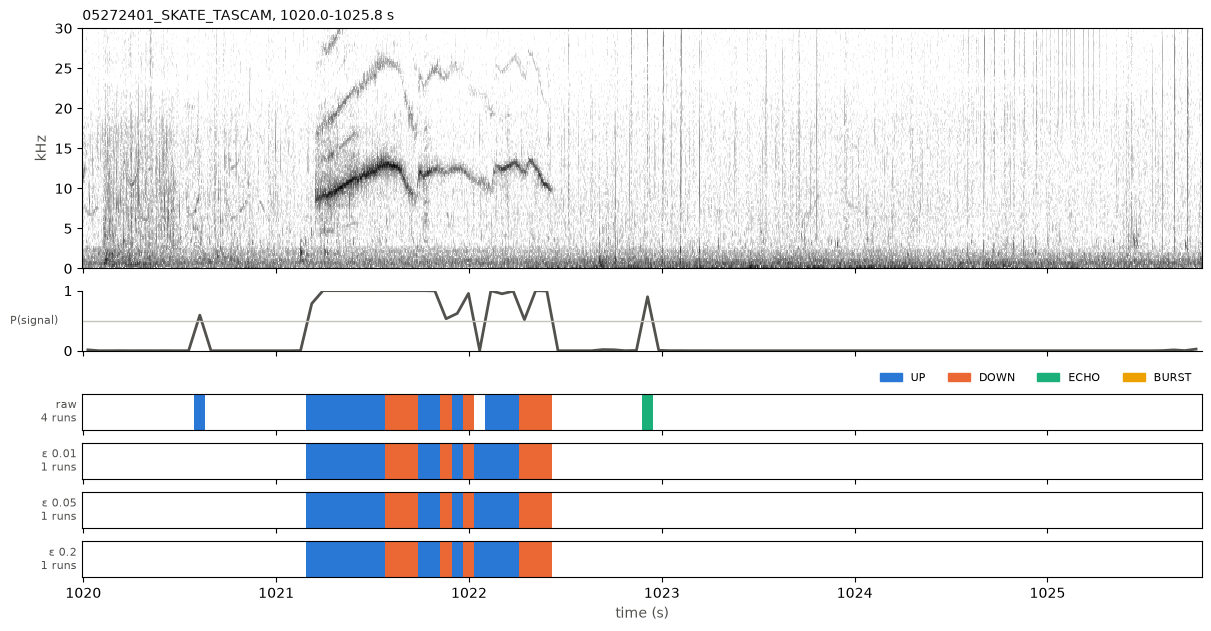

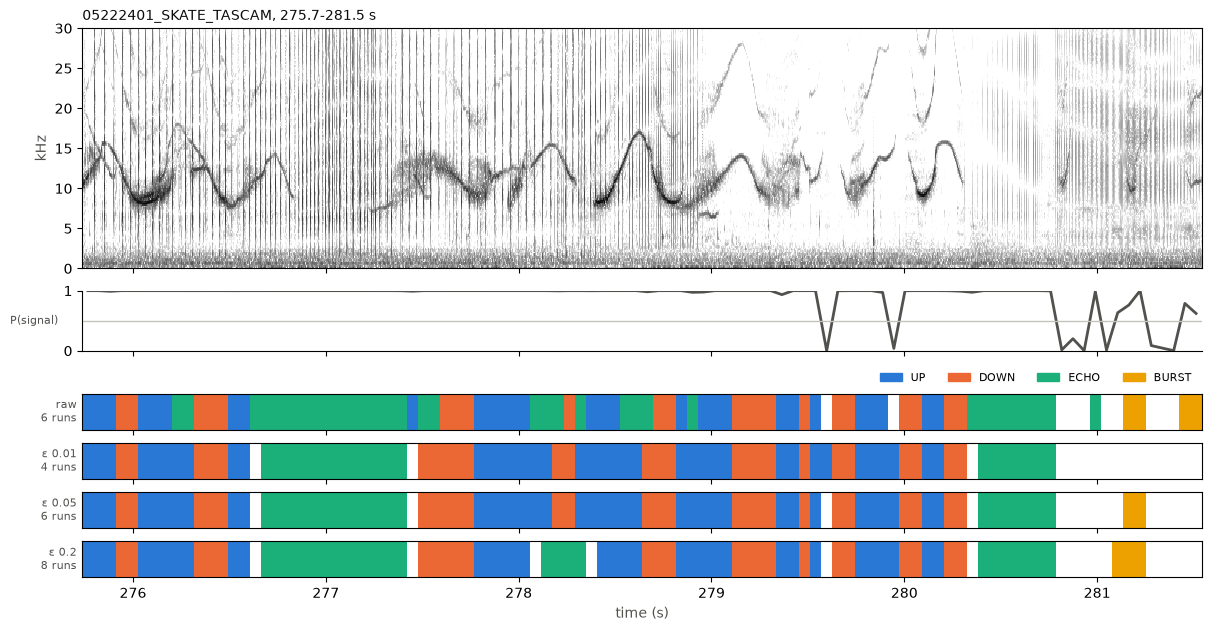

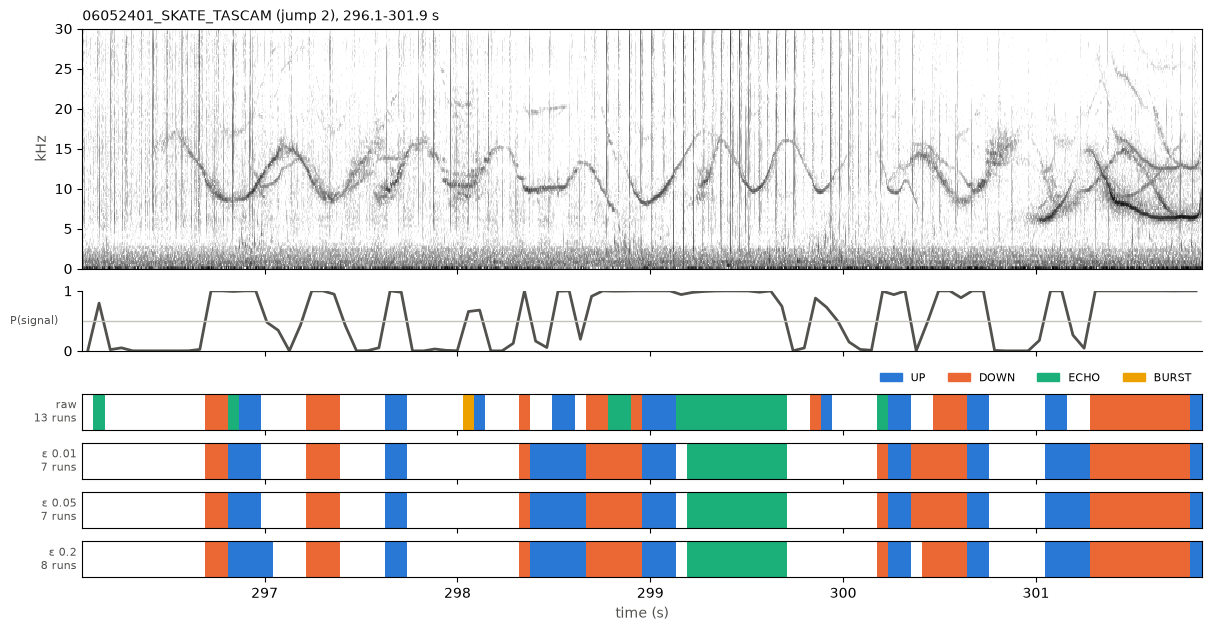

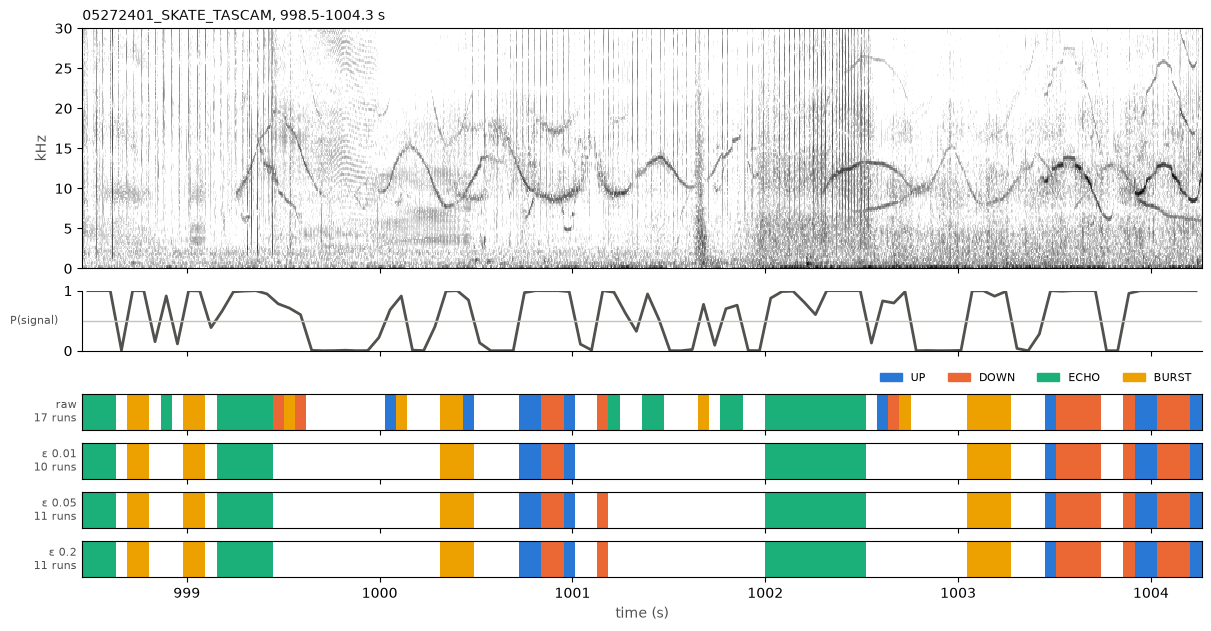

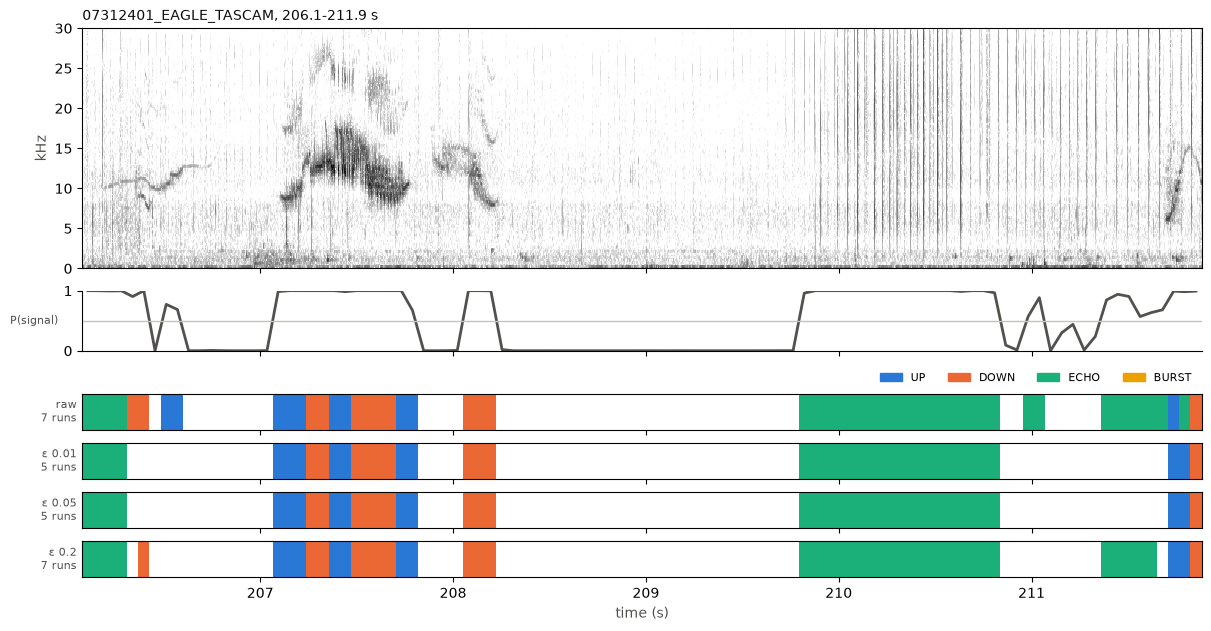

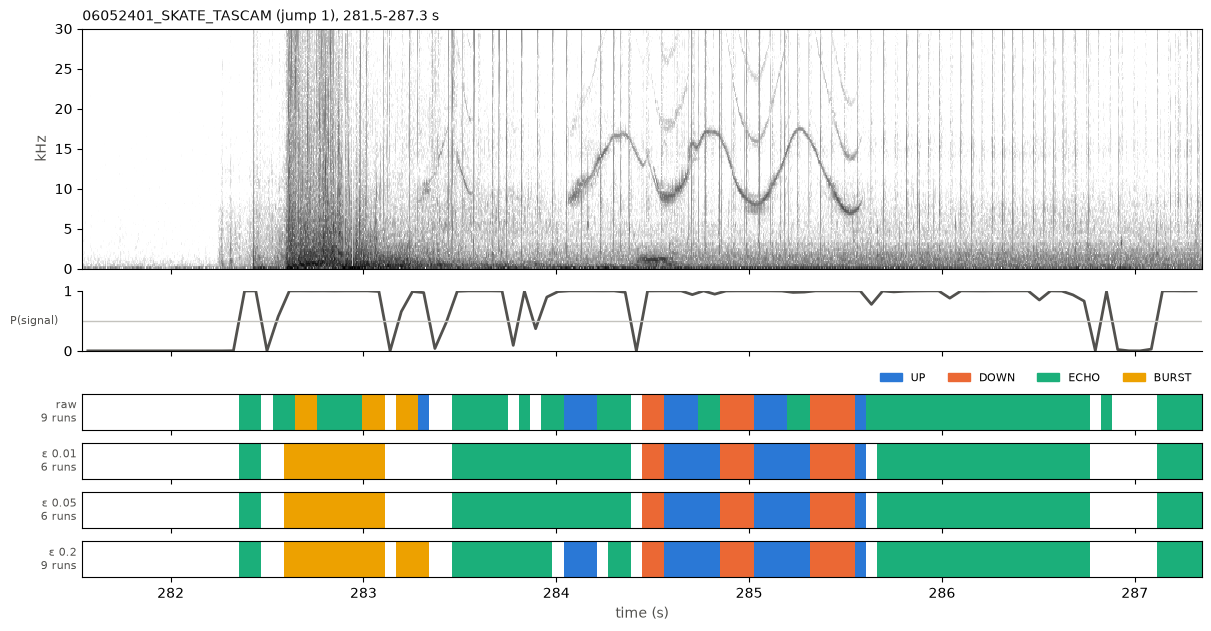

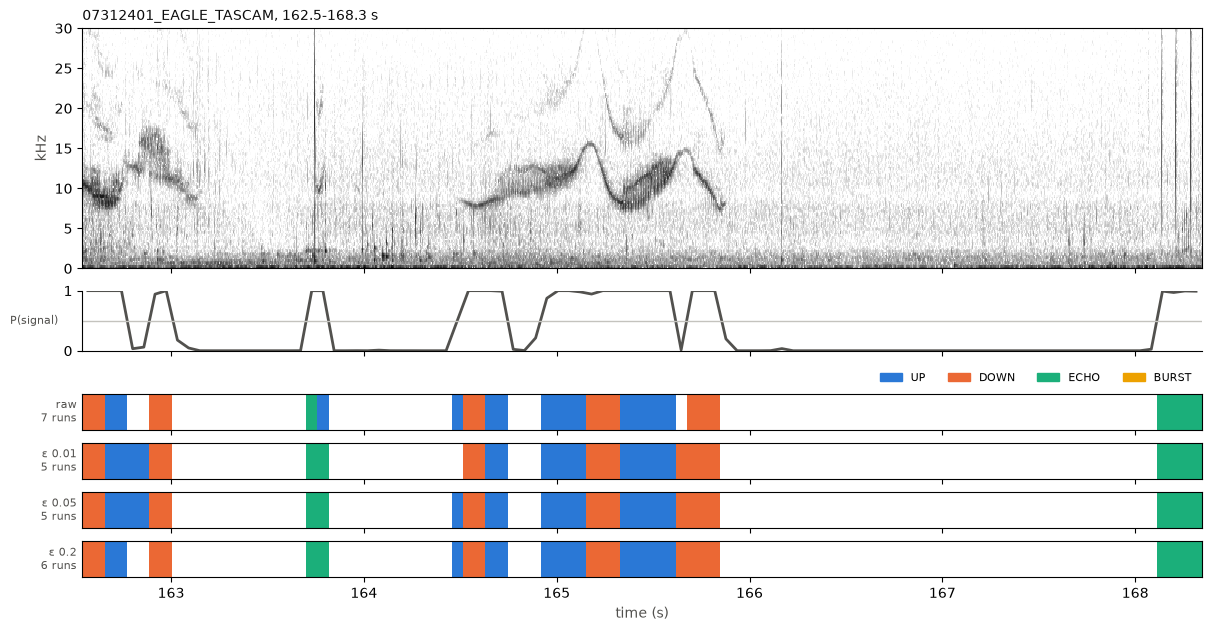

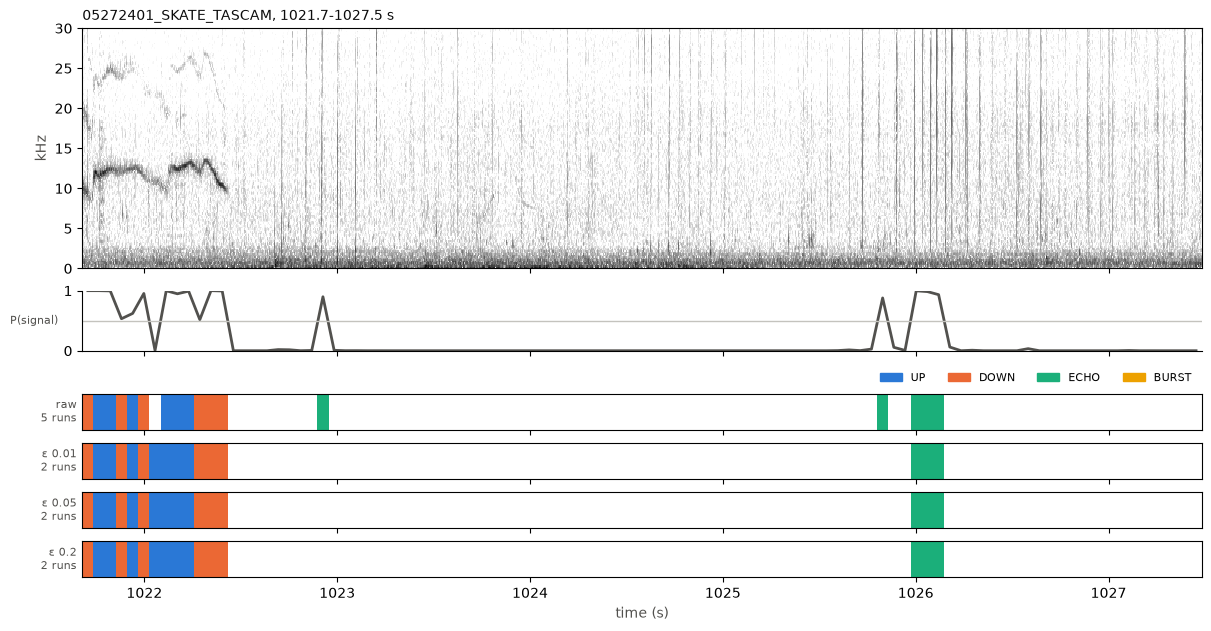

In [8]:
from matplotlib.patches import Patch

def state_colors(rec, seq):
    # WHISTLE frames take the UP / DOWN colour the classifier prefers
    p = probs[rec]
    up_down = np.where(p[:, CLASSIFIER.index('UP')] >= p[:, CLASSIFIER.index('DOWN')], 'UP', 'DOWN')
    return np.where(seq == STATES.index('WHISTLE'), up_down, np.array(STATES)[seq])


def plot_window(rec, start, rows=("raw", "ε 0.01", "ε 0.05", "ε 0.2"), n_fft=512, hop=128):
    import librosa
    offset = SEGMENTS[rec]
    t0, t1 = (offset + start) * STEP_SECONDS, (offset + start + WINDOW) * STEP_SECONDS
    x, sr = load_clip(audio_index[rec], t0, t1)
    fig, axes = plt.subplots(2 + len(rows), 1, figsize=(12, 4.6 + 0.4 * len(rows)), sharex=True, constrained_layout=True,
                             gridspec_kw={'height_ratios': [4, 1] + [0.6] * len(rows)})
    S = librosa.amplitude_to_db(np.abs(librosa.stft(x.astype(np.float32), n_fft=n_fft, hop_length=hop)), ref=np.max)
    axes[0].imshow(S, aspect='auto', origin='lower', cmap='gray_r', vmin=np.percentile(S, 60), vmax=0,
                   extent=(t0, t0 + len(x) / sr, 0, sr / 2 / 1000), interpolation='nearest')
    axes[0].set_ylim(0, (FMAX_HZ or sr / 2) / 1000)
    axes[0].set_ylabel('kHz', color='#52514e')
    axes[0].set_title(f'{rec}, {t0:.1f}-{t1:.1f} s', loc='left', fontsize=10, color='#0b0b0b')

    times = t0 + (np.arange(WINDOW) + 0.5) * STEP_SECONDS
    signal = 1 - (probs[rec] @ MERGE)[start:start + WINDOW, NOISE]
    axes[1].plot(times, signal, color='#52514e', linewidth=2)
    axes[1].axhline(0.5, color='#c4c3be', linewidth=1)
    axes[1].set_ylim(0, 1)
    axes[1].set_yticks([0, 1])
    axes[1].set_ylabel('P(signal)', rotation=0, ha='right', va='center', color='#52514e', fontsize=8)
    axes[1].spines[['top', 'right']].set_visible(False)

    for ax, row in zip(axes[2:], rows):
        seq = states[row][rec][start:start + WINDOW]
        colors = state_colors(rec, states[row][rec])[start:start + WINDOW]
        for label in LABEL_ORDER:
            if label == 'NOISE':
                continue
            for s, e in runs(colors == label):
                ax.axvspan(t0 + s * STEP_SECONDS, t0 + e * STEP_SECONDS, color=LABEL_COLORS[label], lw=0)
        ax.set_yticks([])
        ax.set_ylabel(f"{row}\n{len(signal_runs(seq)[0])} runs", rotation=0, ha='right', va='center',
                      color='#52514e', fontsize=8)
    axes[2].legend(handles=[Patch(color=LABEL_COLORS[l], label=l) for l in LABEL_ORDER if l != 'NOISE'],
                   ncol=4, frameon=False, fontsize=8, loc='lower right', bbox_to_anchor=(1, 1.0))
    axes[-1].set_xlabel('time (s)', color='#52514e')
    axes[-1].set_xlim(t0, t1)
    return fig


for rec, s in examples:
    plot_window(rec, s)
    plt.show()